In [ ]:
import os
import zipfile
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
from google.colab import files

uploaded = files.upload()

zip_file_name = list(uploaded.keys())[0]
print("Uploaded file:", zip_file_name)

Saving archive (14).zip to archive (14) (2).zip
Uploaded file: archive (14) (2).zip


In [ ]:
extract_path = "/content/lung_cancer_dataset"

if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_file_name, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [ ]:
data_root = None

for root, dirs, files in os.walk(extract_path):
    if "train" in dirs and "valid" in dirs and "test" in dirs:
        data_root = root
        break

print("Data root:", data_root)

train_dir = os.path.join(data_root, "train")
valid_dir = os.path.join(data_root, "valid")
test_dir = os.path.join(data_root, "test")

print("Train folder:", train_dir)
print("Valid folder:", valid_dir)
print("Test folder:", test_dir)

Data root: /content/lung_cancer_dataset/Data
Train folder: /content/lung_cancer_dataset/Data/train
Valid folder: /content/lung_cancer_dataset/Data/valid
Test folder: /content/lung_cancer_dataset/Data/test


In [ ]:
def normalize_label(folder_name):
    name = folder_name.lower()

    if "adenocarcinoma" in name:
        return "adenocarcinoma"
    elif "large.cell" in name or "large_cell" in name or "large cell" in name:
        return "large_cell_carcinoma"
    elif "normal" in name:
        return "normal"
    elif "squamous" in name:
        return "squamous_cell_carcinoma"
    else:
        return "unknown"


def create_dataframe(split_dir):
    image_paths = []
    labels = []

    valid_extensions = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

    for class_folder in os.listdir(split_dir):
        class_folder_path = os.path.join(split_dir, class_folder)

        if not os.path.isdir(class_folder_path):
            continue

        label = normalize_label(class_folder)

        for file_name in os.listdir(class_folder_path):
            if file_name.lower().endswith(tuple(valid_extensions)):
                image_paths.append(os.path.join(class_folder_path, file_name))
                labels.append(label)

    df = pd.DataFrame({
        "path": image_paths,
        "label": labels
    })

    df = df[df["label"] != "unknown"].reset_index(drop=True)

    return df


train_df = create_dataframe(train_dir)
valid_df = create_dataframe(valid_dir)
test_df = create_dataframe(test_dir)

print("Train images:", len(train_df))
print("Validation images:", len(valid_df))
print("Test images:", len(test_df))

display(train_df.head())

Train images: 613
Validation images: 72
Test images: 315


,path,label
0,/content/lung_cancer_dataset/Data/train/adenoc...,adenocarcinoma
1,/content/lung_cancer_dataset/Data/train/adenoc...,adenocarcinoma
2,/content/lung_cancer_dataset/Data/train/adenoc...,adenocarcinoma
3,/content/lung_cancer_dataset/Data/train/adenoc...,adenocarcinoma
4,/content/lung_cancer_dataset/Data/train/adenoc...,adenocarcinoma


In [ ]:
print("Train class distribution:")
print(train_df["label"].value_counts())

print("\nValidation class distribution:")
print(valid_df["label"].value_counts())

print("\nTest class distribution:")
print(test_df["label"].value_counts())

Train class distribution:
label
adenocarcinoma             195
squamous_cell_carcinoma    155
normal                     148
large_cell_carcinoma       115
Name: count, dtype: int64

Validation class distribution:
label
adenocarcinoma             23
large_cell_carcinoma       21
squamous_cell_carcinoma    15
normal                     13
Name: count, dtype: int64

Test class distribution:
label
adenocarcinoma             120
squamous_cell_carcinoma     90
normal                      54
large_cell_carcinoma        51
Name: count, dtype: int64


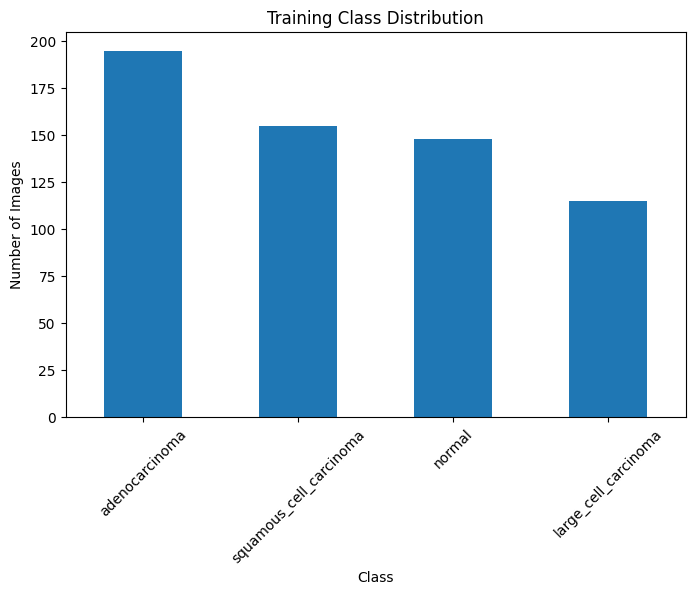

In [ ]:
plt.figure(figsize=(8, 5))
train_df["label"].value_counts().plot(kind="bar")
plt.title("Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

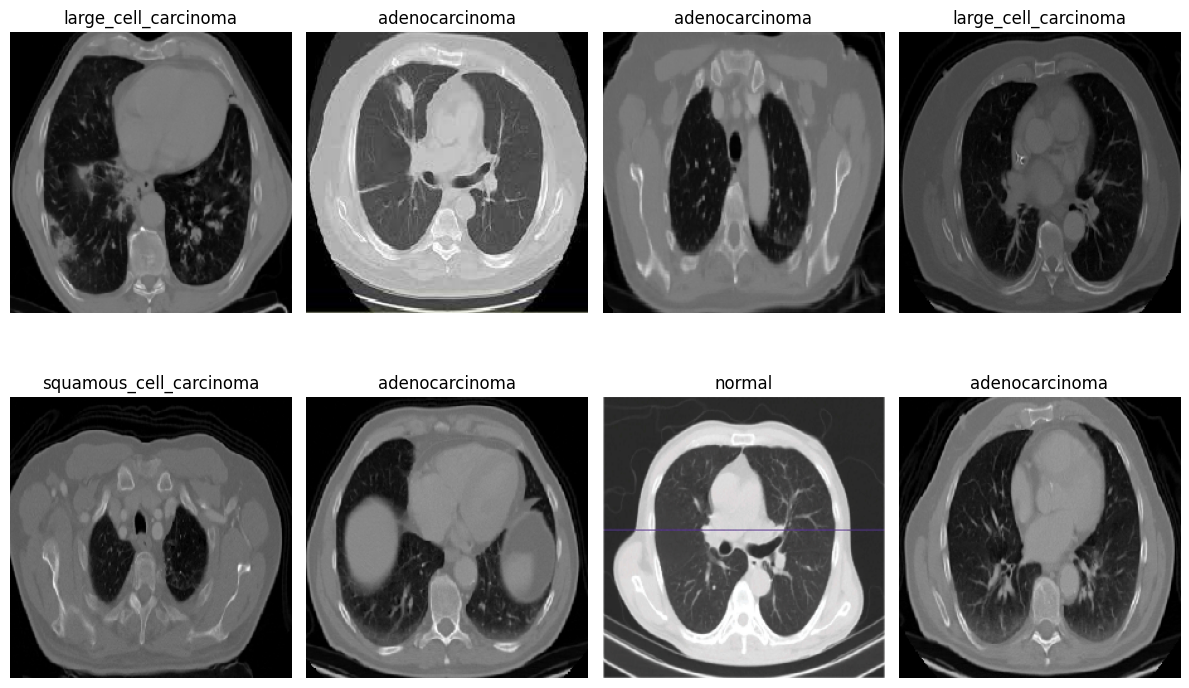

In [ ]:
plt.figure(figsize=(12, 8))

sample_df = train_df.sample(8, random_state=42).reset_index(drop=True)

for i in range(len(sample_df)):
    img = keras.utils.load_img(sample_df.loc[i, "path"], target_size=(224, 224))

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(sample_df.loc[i, "label"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
class_names = [
    "adenocarcinoma",
    "large_cell_carcinoma",
    "normal",
    "squamous_cell_carcinoma"
]

label_to_index = {
    class_name: index for index, class_name in enumerate(class_names)
}

index_to_label = {
    index: class_name for class_name, index in label_to_index.items()
}

train_df["label_index"] = train_df["label"].map(label_to_index)
valid_df["label_index"] = valid_df["label"].map(label_to_index)
test_df["label_index"] = test_df["label"].map(label_to_index)

num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Classes: ['adenocarcinoma', 'large_cell_carcinoma', 'normal', 'squamous_cell_carcinoma']
Number of classes: 4


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def load_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, IMG_SIZE)

    image = tf.cast(image, tf.float32) / 255.0

    return image, label


def create_tf_dataset(df, shuffle=False):
    paths = df["path"].values
    labels = df["label_index"].values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(load_image, num_parallel_calls=AUTOTUNE)

    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(df), seed=42)

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_tf_dataset(train_df, shuffle=True)
val_ds = create_tf_dataset(valid_df, shuffle=False)
test_ds = create_tf_dataset(test_df, shuffle=False)

print("Datasets created successfully.")

Datasets created successfully.


In [ ]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label_index"]),
    y=train_df["label_index"]
)

class_weight_dict = {
    i: class_weights[i] for i in range(len(class_weights))
}

print("Class weights:")
print(class_weight_dict)

Class weights:
{0: np.float64(0.7858974358974359), 1: np.float64(1.3326086956521739), 2: np.float64(1.035472972972973), 3: np.float64(0.9887096774193549)}


In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
])

In [ ]:
base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = keras.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),

    data_augmentation,

    # Convert image range from 0-1 to -1 to +1 for MobileNetV2
    layers.Rescaling(2.0, offset=-1.0),

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.35),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_lung_cancer_mobilenetv2.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=callbacks
)

Epoch 1/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2379 - loss: 2.0268
Epoch 1: val_accuracy improved from None to 0.19444, saving model to best_lung_cancer_mobilenetv2.keras

Epoch 1: finished saving model to best_lung_cancer_mobilenetv2.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.2512 - loss: 1.9040 - val_accuracy: 0.1944 - val_loss: 1.5785
Epoch 2/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2870 - loss: 1.7266
Epoch 2: val_accuracy improved from 0.19444 to 0.26389, saving model to best_lung_cancer_mobilenetv2.keras

Epoch 2: finished saving model to best_lung_cancer_mobilenetv2.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 79s 2s/step - accuracy: 0.2757 - loss: 1.7115 - val_accuracy: 0.2639 - val_loss: 1.4476
Epoch 3/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3180 - loss: 1.5565
Epoch 3: val_accuracy improved from 0.26389 to 0.29167, saving model to best_lung_cancer_mobilenetv2.keras

Epoch 3: finished saving model to best_lung_cancer_mobilenetv2

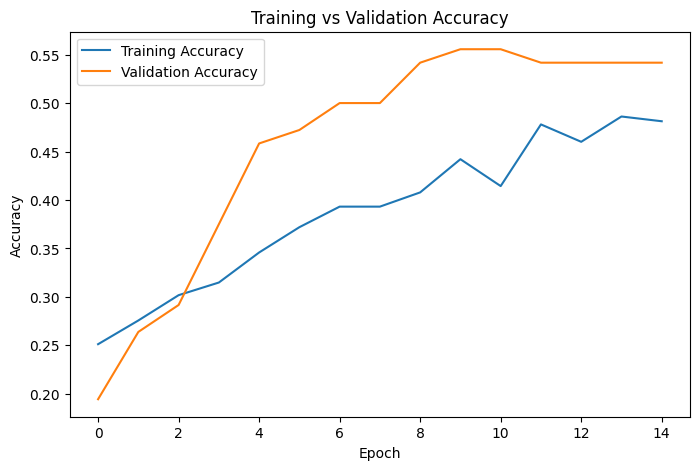

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

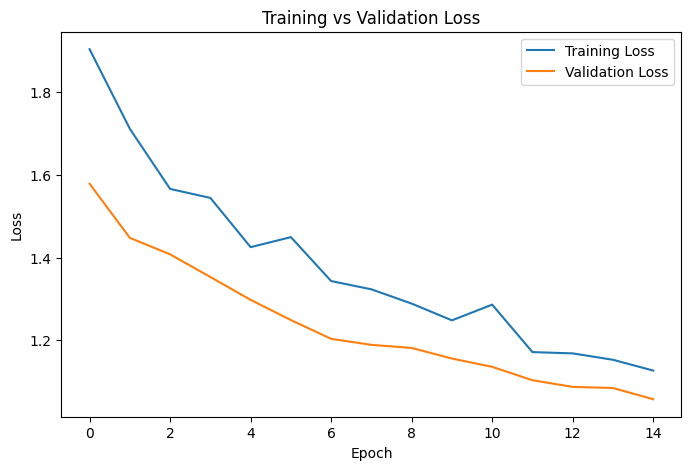

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.5556 - loss: 0.9984
Test Loss: 0.9983759522438049
Test Accuracy: 0.5555555820465088


In [ ]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images)

    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
                         precision    recall  f1-score   support

         adenocarcinoma       0.49      0.88      0.63       120
   large_cell_carcinoma       0.83      0.10      0.18        51
                 normal       0.84      0.98      0.91        54
squamous_cell_carcinoma       0.39      0.13      0.20        90

               accuracy                           0.56       315
              macro avg       0.64      0.52      0.48       315
           weighted avg       0.58      0.56      0.48       315



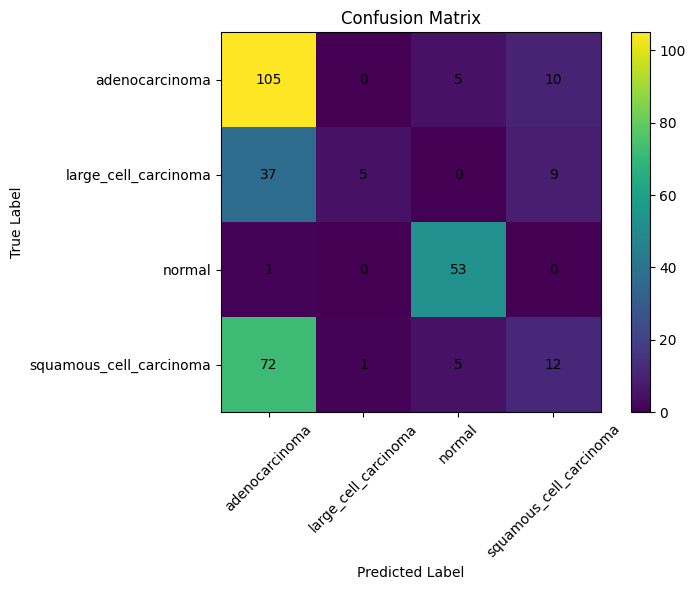

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45)
plt.yticks(tick_marks, class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

Saving 4 (2).png to 4 (2).png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step


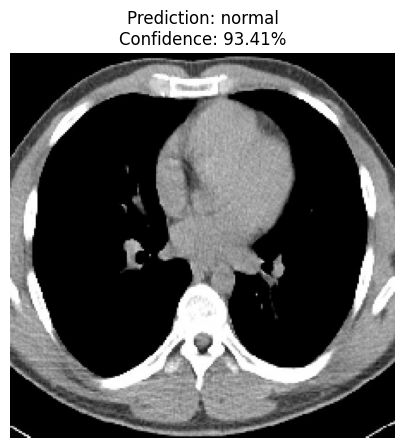

Predicted Class: normal
Confidence: 93.41 %

All Class Probabilities:
adenocarcinoma: 5.65%
large_cell_carcinoma: 0.59%
normal: 93.41%
squamous_cell_carcinoma: 0.35%


In [ ]:
from google.colab import files

uploaded_image = files.upload()

for file_name in uploaded_image.keys():
    image = keras.utils.load_img(file_name, target_size=IMG_SIZE)

    image_array = keras.utils.img_to_array(image)

    # Same normalization as training
    image_array = image_array / 255.0

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    prediction = model.predict(image_array)

    predicted_index = np.argmax(prediction[0])
    predicted_class = index_to_label[predicted_index]
    confidence = np.max(prediction[0]) * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%")
    plt.show()

    print("Predicted Class:", predicted_class)
    print("Confidence:", round(confidence, 2), "%")

    print("\nAll Class Probabilities:")
    for i, prob in enumerate(prediction[0]):
        print(f"{index_to_label[i]}: {prob * 100:.2f}%")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from google.colab import files

# Required image size for MobileNetV2
IMG_SIZE = (224, 224)

# Class names used during training
class_names = [
    "adenocarcinoma",
    "large_cell_carcinoma",
    "normal",
    "squamous_cell_carcinoma"
]

label_to_index = {
    class_name: index for index, class_name in enumerate(class_names)
}

index_to_label = {
    index: class_name for class_name, index in label_to_index.items()
}

print("Setup completed.")
print("Image size:", IMG_SIZE)
print("Classes:", class_names)

Setup completed.
Image size: (224, 224)
Classes: ['adenocarcinoma', 'large_cell_carcinoma', 'normal', 'squamous_cell_carcinoma']


Saving 5.png to 5.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step


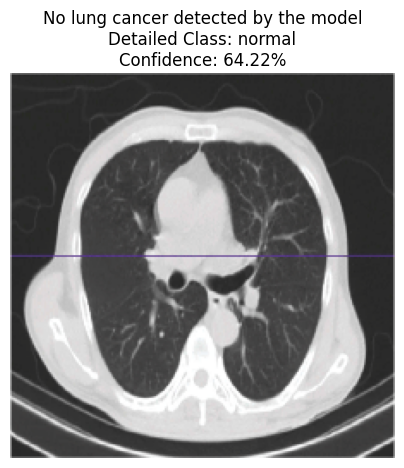

Final User-Friendly Result: No lung cancer detected by the model
Detailed Predicted Class: normal
Prediction Confidence: 64.22 %
Confidence Level: Medium confidence

Cancer Probability: 35.78 %
Normal Probability: 64.22 %

Detailed Class Probabilities:
adenocarcinoma: 20.53%
large_cell_carcinoma: 8.46%
normal: 64.22%
squamous_cell_carcinoma: 6.78%

Important Note:
This is an academic AI prototype, not a medical diagnosis system.
A real diagnosis must be confirmed by a qualified doctor/radiologist.


In [ ]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

uploaded_image = files.upload()

# Cancer classes: all classes except normal
cancer_classes = [
    "adenocarcinoma",
    "large_cell_carcinoma",
    "squamous_cell_carcinoma"
]

for file_name in uploaded_image.keys():
    # Load image
    image = keras.utils.load_img(file_name, target_size=IMG_SIZE)
    image_array = keras.utils.img_to_array(image)

    # Normalize image same as training
    image_array = image_array / 255.0

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Predict
    prediction = model.predict(image_array)[0]

    predicted_index = np.argmax(prediction)
    predicted_class = index_to_label[predicted_index]
    confidence = prediction[predicted_index] * 100

    # Calculate cancer probability by adding all cancer class probabilities
    cancer_probability = 0

    for i, prob in enumerate(prediction):
        class_name = index_to_label[i]

        if class_name in cancer_classes:
            cancer_probability += prob

    cancer_probability = cancer_probability * 100

    normal_probability = prediction[label_to_index["normal"]] * 100

    # User-friendly decision
    if predicted_class == "normal":
        final_result = "No lung cancer detected by the model"
    else:
        final_result = "Lung cancer suspected by the model"

    # Confidence level
    if confidence >= 80:
        confidence_level = "High confidence"
    elif confidence >= 60:
        confidence_level = "Medium confidence"
    else:
        confidence_level = "Low confidence / uncertain prediction"

    # Display image
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"{final_result}\n"
        f"Detailed Class: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    print("Final User-Friendly Result:", final_result)
    print("Detailed Predicted Class:", predicted_class)
    print("Prediction Confidence:", round(confidence, 2), "%")
    print("Confidence Level:", confidence_level)

    print("\nCancer Probability:", round(cancer_probability, 2), "%")
    print("Normal Probability:", round(normal_probability, 2), "%")

    print("\nDetailed Class Probabilities:")
    for i, prob in enumerate(prediction):
        print(f"{index_to_label[i]}: {prob * 100:.2f}%")

    print("\nImportant Note:")
    print("This is an academic AI prototype, not a medical diagnosis system.")
    print("A real diagnosis must be confirmed by a qualified doctor/radiologist.")

In [ ]:
model.save("final_lung_cancer_mobilenetv2_model.keras")

print("Model saved successfully.")

Model saved successfully.


In [ ]:
from google.colab import files

files.download("final_lung_cancer_mobilenetv2_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>